# 02 · Kỹ Thuật Đặc Trưng Chống Rò Rỉ & Offline/Online Parity (BR-07 · ML-DL-01..06)
**Dự án:** SentinelRisk AI — Real-Time Fraud & Transaction Risk Detection Platform  
**Mục tiêu:** Xây dựng bộ **71 đặc trưng sạch, 100% nhân quả (strictly past-only)** trên toàn bộ **590,540 giao dịch IEEE-CIS** (chia thời gian 60/20/20: Train 354K · Val 118K · Test 118K), đảm bảo:
- **Zero Lookahead Leakage (`ML-DL-01`, `ML-DL-02`):** Toàn bộ đặc trưng Velocity (`txn_count_1h`, `txn_count_24h`, `amount_sum_1h`, `time_since_last_txn`), Behavioural (`card1_avg_amount_hist`, `amount_ratio_hist`) và Novelty (`new_device_flag`, `new_addr_flag`, `new_product_flag`, `new_email_flag`) chỉ sử dụng các giao dịch **xảy ra trước thời điểm hiện tại**.
- **Train-Only Encoding (`ML-DL-04`):** Từ điển mã hóa categorical, tần suất xuất hiện (`*_freq`) và trung bình số tiền theo `ProductCD` chỉ fit trên tập **Train**, sau đó ánh xạ sang Val/Test.
- **Offline ↔ Online Feature Parity (`BR-07`):** Ánh xạ trực tiếp sang 8 đặc trưng thời gian thực trên Redis của hệ thống SentinelRisk AI.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore")

# Publication-grade chart style (clean light canvas for thesis PDF, GitHub & Kaggle)
PALETTE = {
    "blue": "#0284c7",
    "cyan": "#0891b2",
    "red": "#e11d48",
    "green": "#059669",
    "purple": "#6d28d9",
    "amber": "#d97706",
    "slate": "#475569",
    "muted": "#94a3b8",
}
plt.rcParams.update({
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#f8fafc",
    "axes.edgecolor": "#cbd5e1",
    "axes.linewidth": 0.9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#cbd5e1",
    "grid.linestyle": "--",
    "grid.alpha": 0.45,
    "font.sans-serif": ["DejaVu Sans"],
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.frameon": True,
    "legend.facecolor": "#ffffff",
    "legend.edgecolor": "#e2e8f0",
    "figure.dpi": 120,
})

# Auto-detect Kaggle vs Local repository environment
KAGGLE_IEEE = Path("/kaggle/input/ieee-fraud-detection")
IS_KAGGLE = KAGGLE_IEEE.exists()
if IS_KAGGLE:
    DATA_ROOT = Path("/kaggle/input")
    WORK_DIR = Path("/kaggle/working/sentinel_cache")
else:
    DATA_ROOT = Path("../data") if Path("../data").exists() else Path("data")
    WORK_DIR = DATA_ROOT / "features" / "ieee_cis"
WORK_DIR.mkdir(parents=True, exist_ok=True)

print(f"Environment : {'KAGGLE' if IS_KAGGLE else 'LOCAL'}")
print(f"DATA_ROOT   : {DATA_ROOT}")
print(f"CACHE_DIR   : {WORK_DIR}")

Environment : LOCAL
DATA_ROOT   : ..\data
CACHE_DIR   : ..\data\features\ieee_cis


## 1. Định Nghĩa Pipeline Đặc Trưng Nhân Quả (Causal Vectorized — O(N log N))

In [2]:
TOP_V_COLS = [
    "V257", "V258", "V246", "V244", "V242", "V201", "V189",
    "V45", "V87", "V91", "V156", "V294", "V308", "V317",
]
CAT_COLS = ["ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain", "DeviceType"]
FREQ_COLS = ["card1", "addr1", "P_emaildomain"]
C_COLS = [f"C{i}" for i in range(1, 15)]
D_COLS = ["D1", "D2", "D3", "D4", "D10", "D15"]
NUM_RAW_COLS = ["card1", "card2", "card3", "card5", "addr1", "addr2", "dist1", "dist2"]

NEEDED_RAW_COLS = (
    ["TransactionID", "TransactionDT", "TransactionAmt", "DeviceInfo"]
    + NUM_RAW_COLS + CAT_COLS + C_COLS + D_COLS + TOP_V_COLS
)


def _compute_causal_card_features(
    df_all: pd.DataFrame, train_median_amt: float
) -> pd.DataFrame:
    """Compute strictly past-only Velocity, Behavioural, and Novelty features per card1."""
    n = len(df_all)
    card1 = df_all["card1"].fillna(-1).to_numpy(dtype=np.int64)
    dt = df_all["TransactionDT"].to_numpy(dtype=np.int64)
    amt = df_all["TransactionAmt"].fillna(0.0).to_numpy(dtype=np.float64)

    order = np.lexsort((dt, card1))
    c_s, t_s, a_s = card1[order], dt[order], amt[order]
    prefix_a = np.concatenate(([0.0], np.cumsum(a_s)))
    bounds = np.flatnonzero(np.diff(c_s)) + 1
    starts = np.concatenate(([0], bounds))
    ends = np.concatenate((bounds, [n]))

    cnt_1h = np.zeros(n, dtype=np.int32)
    cnt_24h = np.zeros(n, dtype=np.int32)
    sum_1h = np.zeros(n, dtype=np.float64)
    dt_diff = np.full(n, -1.0, dtype=np.float64)
    prev_cnt = np.zeros(n, dtype=np.int32)
    prev_sum = np.zeros(n, dtype=np.float64)

    for s, e in zip(starts, ends):
        m = e - s
        if m <= 1:
            continue
        tg = t_s[s:e]
        idx = np.arange(m)
        l1 = np.searchsorted(tg, tg - 3600, side="left")
        l24 = np.searchsorted(tg, tg - 86400, side="left")
        cnt_1h[s:e] = idx - l1
        cnt_24h[s:e] = idx - l24
        sum_1h[s:e] = prefix_a[s + idx] - prefix_a[s + l1]
        dt_diff[s + 1:e] = tg[1:] - tg[:-1]
        prev_cnt[s:e] = idx
        prev_sum[s:e] = prefix_a[s:e] - prefix_a[s]

    def _restore(arr: np.ndarray) -> np.ndarray:
        out = np.empty_like(arr)
        out[order] = arr
        return out

    p_cnt = _restore(prev_cnt)
    p_sum = _restore(prev_sum)
    avg_hist = np.where(p_cnt > 0, p_sum / np.maximum(p_cnt, 1), train_median_amt)

    # Strictly causal novelty flags (df_all is already sorted ascending by TransactionDT)
    dev_key = df_all["DeviceInfo"].astype("string").fillna("MISSING").str.slice(0, 20)
    addr_key = df_all["addr1"].fillna(-1).astype("int32")
    prod_key = df_all["ProductCD"].astype("string").fillna("MISSING")
    mail_key = df_all["P_emaildomain"].astype("string").fillna("MISSING")
    c_key = df_all["card1"].fillna(-1).astype("int32")

    return pd.DataFrame({
        "txn_count_1h": _restore(cnt_1h).astype("float32"),
        "txn_count_24h": _restore(cnt_24h).astype("float32"),
        "amount_sum_1h": _restore(sum_1h).astype("float32"),
        "time_since_last_txn": _restore(dt_diff).astype("float32"),
        "card1_prev_txn_count": p_cnt.astype("float32"),
        "card1_avg_amount_hist": avg_hist.astype("float32"),
        "amount_ratio_hist": (amt / (avg_hist + 1.0)).astype("float32"),
        "new_device_flag": (df_all.groupby([c_key, dev_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
        "new_addr_flag": (df_all.groupby([c_key, addr_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
        "new_product_flag": (df_all.groupby([c_key, prod_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
        "new_email_flag": (df_all.groupby([c_key, mail_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
    }, index=df_all.index)


def build_ieee_features_from_splits(
    train_raw: pd.DataFrame,
    val_raw: pd.DataFrame,
    test_raw: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, dict[str, list[str]]]:
    """Build 51 leak-free features across chronological Train/Val/Test splits."""
    n_tr, n_va = len(train_raw), len(val_raw)
    df_all = pd.concat([train_raw, val_raw, test_raw], ignore_index=True)

    # Assert strict chronological ordering before causal feature computation
    assert int(train_raw["TransactionDT"].max()) <= int(val_raw["TransactionDT"].min())
    assert int(val_raw["TransactionDT"].max()) <= int(test_raw["TransactionDT"].min())

    train_median_amt = float(train_raw["TransactionAmt"].median())
    prod_means = train_raw.groupby("ProductCD", observed=False)["TransactionAmt"].mean().to_dict()

    out = pd.DataFrame(index=df_all.index)
    amt = df_all["TransactionAmt"].fillna(0.0).astype("float32")
    out["TransactionAmt"] = amt
    out["amount_log"] = np.log1p(np.maximum(0.0, amt)).astype("float32")
    out["amount_cents"] = (amt - np.floor(amt)).astype("float32")
    out["is_round_amount"] = ((amt % 1.0) == 0).astype("int8")
    out["hour_of_day"] = ((df_all["TransactionDT"] // 3600) % 24).astype("int8")
    out["day_of_week"] = ((df_all["TransactionDT"] // 86400) % 7).astype("int8")

    for col in NUM_RAW_COLS + C_COLS + D_COLS + TOP_V_COLS:
        if col in df_all.columns:
            out[col] = df_all[col].astype("float32").fillna(-999.0)

    p_mail = df_all["P_emaildomain"].astype("string").fillna("MISSING")
    r_mail = df_all["R_emaildomain"].astype("string").fillna("MISSING")
    out["same_email_domain"] = ((p_mail == r_mail) & (p_mail != "MISSING")).astype("int8")
    out["has_device_info"] = df_all["DeviceInfo"].notna().astype("int8")

    # Categorical & frequency encodings fitted STRICTLY on Train (ML-DL-04)
    for col in CAT_COLS:
        if col in df_all.columns:
            s_all = df_all[col].astype("string").fillna("MISSING")
            vocab = {v: i for i, v in enumerate(s_all.iloc[:n_tr].unique())}
            out[col] = s_all.map(vocab).fillna(-1).astype("int16")
    for col in FREQ_COLS:
        if col in df_all.columns:
            s_all = df_all[col].astype("string").fillna("MISSING")
            freq = s_all.iloc[:n_tr].value_counts(normalize=True).to_dict()
            out[f"{col}_freq"] = s_all.map(freq).fillna(0.0).astype("float32")

    base_cols = list(out.columns)

    # Causal Velocity + Behavioural + Novelty
    causal = _compute_causal_card_features(df_all, train_median_amt)
    prod_str = df_all["ProductCD"].astype("string").fillna("MISSING")
    prod_mean_s = prod_str.map({str(k): float(v) for k, v in prod_means.items()}).fillna(train_median_amt)
    causal["amt_to_product_mean"] = (amt / (prod_mean_s.astype("float32") + 1.0)).astype("float32")

    out = pd.concat([out, causal], axis=1)
    if "isFraud" in df_all.columns:
        out["isFraud"] = df_all["isFraud"].fillna(-1).astype("int8")
    out["TransactionDT"] = df_all["TransactionDT"].astype("int32")

    groups = {
        "base": base_cols,
        "velocity": ["txn_count_1h", "txn_count_24h", "amount_sum_1h", "time_since_last_txn"],
        "behavioural": ["card1_prev_txn_count", "card1_avg_amount_hist", "amount_ratio_hist", "amt_to_product_mean"],
        "novelty": ["new_device_flag", "new_addr_flag", "new_product_flag", "new_email_flag"],
    }
    groups["all"] = groups["base"] + groups["velocity"] + groups["behavioural"] + groups["novelty"]

    tr = out.iloc[:n_tr].reset_index(drop=True)
    va = out.iloc[n_tr:n_tr + n_va].reset_index(drop=True)
    te = out.iloc[n_tr + n_va:].reset_index(drop=True)
    return tr, va, te, groups


def load_ieee_rich() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, dict[str, list[str]]]:
    """Load cached IEEE-CIS 51-feature parquets, or build causally on-the-fly (Kaggle & Local)."""
    cache_tr = WORK_DIR / "rich_train.parquet"
    cache_va = WORK_DIR / "rich_val.parquet"
    cache_te = WORK_DIR / "rich_test.parquet"
    cache_gr = WORK_DIR / "feature_groups.json"
    if cache_tr.exists() and cache_va.exists() and cache_te.exists() and cache_gr.exists():
        groups = json.loads(cache_gr.read_text(encoding="utf-8"))
        return pd.read_parquet(cache_tr), pd.read_parquet(cache_va), pd.read_parquet(cache_te), groups

    if IS_KAGGLE:
        txn = pd.read_csv(KAGGLE_IEEE / "train_transaction.csv")
        idt = pd.read_csv(KAGGLE_IEEE / "train_identity.csv")
        df = txn.merge(idt, on="TransactionID", how="left").sort_values("TransactionDT").reset_index(drop=True)
        keep = [c for c in NEEDED_RAW_COLS + ["isFraud"] if c in df.columns]
        df = df[keep]
        n = len(df)
        tr_r, va_r, te_r = df.iloc[:int(n * 0.6)], df.iloc[int(n * 0.6):int(n * 0.8)], df.iloc[int(n * 0.8):]
    else:
        pdir = DATA_ROOT / "processed" / "ieee_cis"
        avail = set(pd.read_parquet(pdir / "train_merged.parquet", columns=["TransactionID"]).columns)
        import pyarrow.parquet as pq
        schema_cols = set(pq.ParquetFile(pdir / "train_merged.parquet").schema.names)
        keep = [c for c in NEEDED_RAW_COLS + ["isFraud"] if c in schema_cols]
        tr_r = pd.read_parquet(pdir / "train_merged.parquet", columns=keep)
        va_r = pd.read_parquet(pdir / "val_merged.parquet", columns=keep)
        te_r = pd.read_parquet(pdir / "test_merged.parquet", columns=keep)

    tr, va, te, groups = build_ieee_features_from_splits(tr_r, va_r, te_r)
    tr.to_parquet(cache_tr, index=False, compression="snappy")
    va.to_parquet(cache_va, index=False, compression="snappy")
    te.to_parquet(cache_te, index=False, compression="snappy")
    cache_gr.write_text(json.dumps(groups, indent=2), encoding="utf-8")
    return tr, va, te, groups

## 2. Thực Thi Tạo Đặc Trưng & Kiểm Định Chống Rò Rỉ Dữ Liệu (ML-DL-01..06)

In [3]:
t0 = time.perf_counter()
# Force fresh rebuild when running Notebook 02 so cache is always up-to-date
for fname in ("rich_train.parquet", "rich_val.parquet", "rich_test.parquet", "feature_groups.json"):
    p = WORK_DIR / fname
    if p.exists():
        p.unlink()

tr_df, va_df, te_df, feat_groups = load_ieee_rich()
elapsed = time.perf_counter() - t0
print(f"Hoàn tất tạo {len(feat_groups['all'])} đặc trưng trên {len(tr_df)+len(va_df)+len(te_df):,} giao dịch trong {elapsed:.2f}s!")

# Automated Anti-Leakage Audit (ML-DL-01..06)
assert tr_df["TransactionDT"].max() <= va_df["TransactionDT"].min(), "ML-DL-02 VIOLATION: Train overlaps Val!"
assert va_df["TransactionDT"].max() <= te_df["TransactionDT"].min(), "ML-DL-02 VIOLATION: Val overlaps Test!"

forbidden = ("chargeback", "confirmed", "review", "decision", "label", "target")
leaked_cols = [c for c in feat_groups["all"] if any(f in c.lower() for f in forbidden)]
assert not leaked_cols, f"ML-DL-03 VIOLATION: {leaked_cols}"

causal_cols = feat_groups["velocity"] + feat_groups["behavioural"] + feat_groups["novelty"]
assert not tr_df[causal_cols].isna().any().any(), "Unexpected NaN in causal features"
assert np.isfinite(tr_df[causal_cols].to_numpy()).all(), "Unexpected Inf in causal features"

audit_df = pd.DataFrame([
    {"Split": "Train (60%)", "Rows": len(tr_df), "Fraud Rate (%)": round(tr_df["isFraud"].mean() * 100, 3), "DT Min": int(tr_df["TransactionDT"].min()), "DT Max": int(tr_df["TransactionDT"].max())},
    {"Split": "Val   (20%)", "Rows": len(va_df), "Fraud Rate (%)": round(va_df["isFraud"].mean() * 100, 3), "DT Min": int(va_df["TransactionDT"].min()), "DT Max": int(va_df["TransactionDT"].max())},
    {"Split": "Test  (20%)", "Rows": len(te_df), "Fraud Rate (%)": round(te_df["isFraud"].mean() * 100, 3), "DT Min": int(te_df["TransactionDT"].min()), "DT Max": int(te_df["TransactionDT"].max())},
])
display(audit_df)
print("\n[PASS] ML-DL-01..06 Anti-Leakage Audit: 100% Đạt chuẩn (Chronological + Causal + Train-only encoding).")
print("Phân nhóm đặc trưng:", {k: len(v) for k, v in feat_groups.items()})

Hoàn tất tạo 71 đặc trưng trên 590,540 giao dịch trong 9.33s!


,Split,Rows,Fraud Rate (%),DT Min,DT Max
0,Train (60%),354324,3.383,86400,8745772
1,Val (20%),118108,3.904,8745798,12192842
2,Test (20%),118108,3.441,12192900,15811131



[PASS] ML-DL-01..06 Anti-Leakage Audit: 100% Đạt chuẩn (Chronological + Causal + Train-only encoding).
Phân nhóm đặc trưng: {'base': 59, 'velocity': 4, 'behavioural': 4, 'novelty': 4, 'all': 71}


## 3. Đánh Giá Sức Mạnh Phân Tách Gian Lận Của Các Đặc Trưng Tự Tạo (Lift Analysis)

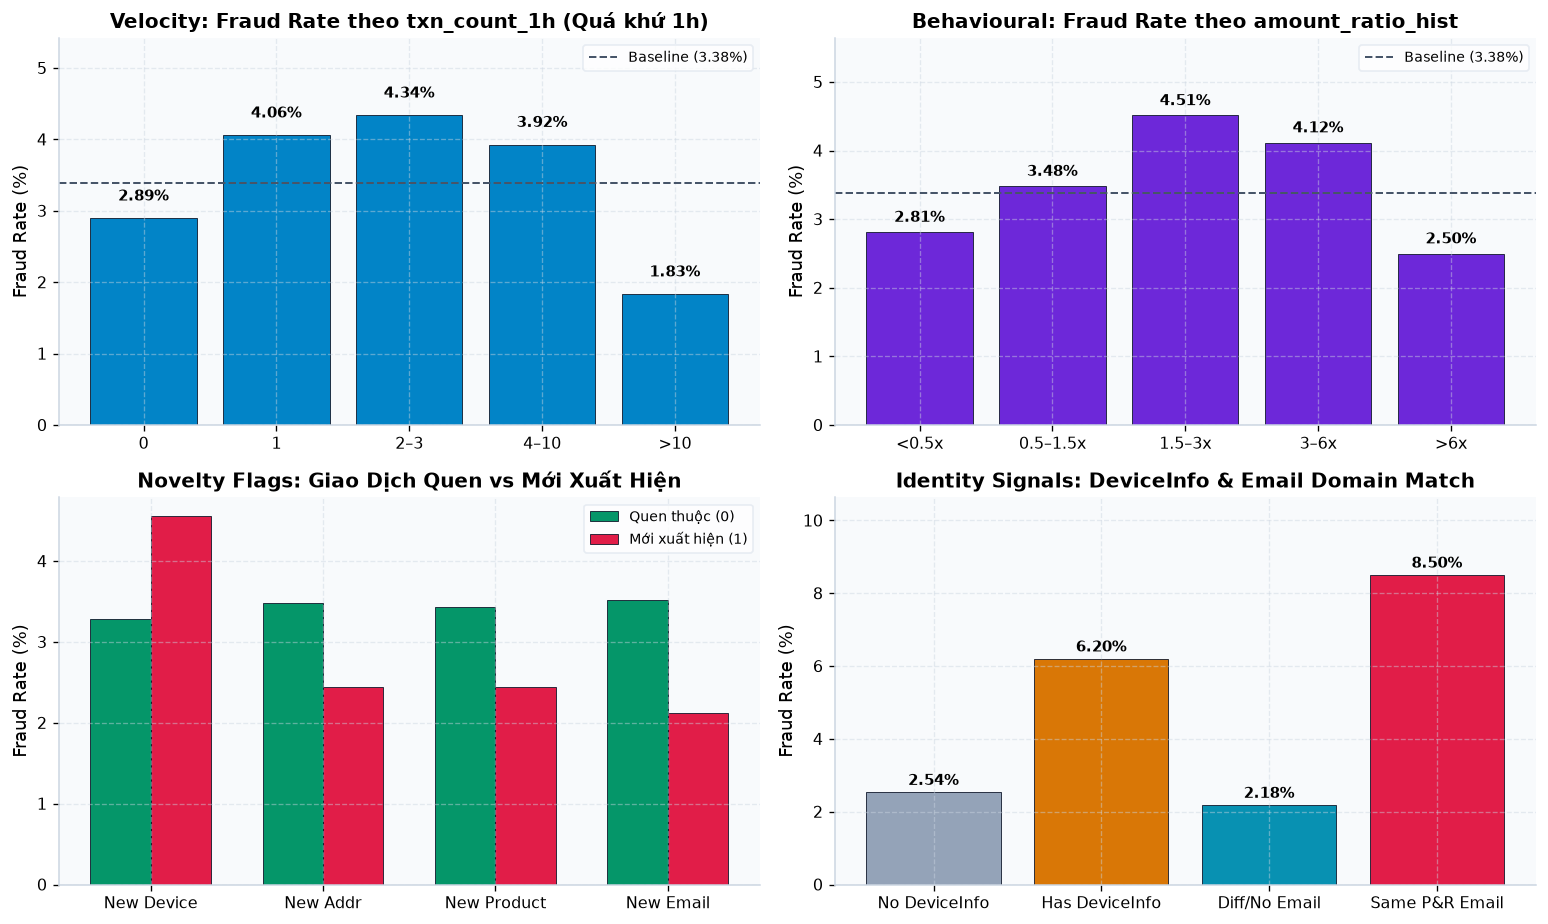

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.8))
base_rate = tr_df["isFraud"].mean() * 100

# 1) Velocity: txn_count_1h buckets
ax = axes[0, 0]
bins_v = pd.cut(tr_df["txn_count_1h"], bins=[-1, 0, 1, 3, 10, 1e9], labels=["0", "1", "2–3", "4–10", ">10"])
s1 = tr_df.groupby(bins_v, observed=False)["isFraud"].mean() * 100
bars = ax.bar(s1.index.astype(str), s1.values, color=PALETTE["blue"], edgecolor="#0f172a", linewidth=0.5)
ax.axhline(base_rate, color=PALETTE["slate"], ls="--", lw=1.2, label=f"Baseline ({base_rate:.2f}%)")
for b, v in zip(bars, s1.values):
    ax.text(b.get_x() + b.get_width()/2, v + 0.25, f"{v:.2f}%", ha="center", fontsize=8.8, fontweight="bold")
ax.set_title("Velocity: Fraud Rate theo txn_count_1h (Quá khứ 1h)")
ax.set_ylabel("Fraud Rate (%)"); ax.set_ylim(0, max(s1.values) * 1.25); ax.legend(fontsize=8.5)

# 2) Behavioural: amount_ratio_hist buckets
ax = axes[0, 1]
bins_b = pd.cut(tr_df["amount_ratio_hist"], bins=[-1, 0.5, 1.5, 3.0, 6.0, 1e9], labels=["<0.5x", "0.5–1.5x", "1.5–3x", "3–6x", ">6x"])
s2 = tr_df.groupby(bins_b, observed=False)["isFraud"].mean() * 100
bars = ax.bar(s2.index.astype(str), s2.values, color=PALETTE["purple"], edgecolor="#0f172a", linewidth=0.5)
ax.axhline(base_rate, color=PALETTE["slate"], ls="--", lw=1.2, label=f"Baseline ({base_rate:.2f}%)")
for b, v in zip(bars, s2.values):
    ax.text(b.get_x() + b.get_width()/2, v + 0.15, f"{v:.2f}%", ha="center", fontsize=8.8, fontweight="bold")
ax.set_title("Behavioural: Fraud Rate theo amount_ratio_hist")
ax.set_ylabel("Fraud Rate (%)"); ax.set_ylim(0, max(s2.values) * 1.25); ax.legend(fontsize=8.5)

# 3) Novelty flags comparison
ax = axes[1, 0]
nov_rows = []
for col, lbl in [("new_device_flag", "New Device"), ("new_addr_flag", "New Addr"), ("new_product_flag", "New Product"), ("new_email_flag", "New Email")]:
    r0 = tr_df.loc[tr_df[col] == 0, "isFraud"].mean() * 100
    r1 = tr_df.loc[tr_df[col] == 1, "isFraud"].mean() * 100
    nov_rows.append((lbl, r0, r1))
x = np.arange(len(nov_rows)); w = 0.35
ax.bar(x - w/2, [r[1] for r in nov_rows], w, label="Quen thuộc (0)", color=PALETTE["green"], edgecolor="#0f172a", linewidth=0.5)
ax.bar(x + w/2, [r[2] for r in nov_rows], w, label="Mới xuất hiện (1)", color=PALETTE["red"], edgecolor="#0f172a", linewidth=0.5)
ax.set_xticks(x); ax.set_xticklabels([r[0] for r in nov_rows])
ax.set_title("Novelty Flags: Giao Dịch Quen vs Mới Xuất Hiện")
ax.set_ylabel("Fraud Rate (%)"); ax.legend(fontsize=8.5)

# 4) Email match & Device presence
ax = axes[1, 1]
sig_names = ["No DeviceInfo", "Has DeviceInfo", "Diff/No Email", "Same P&R Email"]
sig_vals = [
    tr_df.loc[tr_df["has_device_info"] == 0, "isFraud"].mean() * 100,
    tr_df.loc[tr_df["has_device_info"] == 1, "isFraud"].mean() * 100,
    tr_df.loc[tr_df["same_email_domain"] == 0, "isFraud"].mean() * 100,
    tr_df.loc[tr_df["same_email_domain"] == 1, "isFraud"].mean() * 100,
]
bars = ax.bar(sig_names, sig_vals, color=[PALETTE["muted"], PALETTE["amber"], PALETTE["cyan"], PALETTE["red"]], edgecolor="#0f172a", linewidth=0.5)
for b, v in zip(bars, sig_vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.2, f"{v:.2f}%", ha="center", fontsize=8.8, fontweight="bold")
ax.set_title("Identity Signals: DeviceInfo & Email Domain Match")
ax.set_ylabel("Fraud Rate (%)"); ax.set_ylim(0, max(sig_vals) * 1.25)

plt.tight_layout()
plt.show()

## 4. Bảng Đối Chiếu Offline ↔ Online Feature Parity (BR-07)

In [5]:
parity_table = pd.DataFrame([
    {"Nhóm": "Velocity", "Online Redis Feature (SentinelRisk)": "txn_count_5m / txn_count_1h", "Offline IEEE-CIS Feature": "txn_count_1h, txn_count_24h", "Chống Leakage": "Strict < TransactionDT (searchsorted)"},
    {"Nhóm": "Velocity", "Online Redis Feature (SentinelRisk)": "amount_sum_1h", "Offline IEEE-CIS Feature": "amount_sum_1h", "Chống Leakage": "Prefix sum exclusive of current row"},
    {"Nhóm": "Velocity", "Online Redis Feature (SentinelRisk)": "unique_merchants_1h", "Offline IEEE-CIS Feature": "time_since_last_txn, C1..C14", "Chống Leakage": "Past-only inter-arrival delta"},
    {"Nhóm": "Behavioural", "Online Redis Feature (SentinelRisk)": "avg_amount_30d", "Offline IEEE-CIS Feature": "card1_avg_amount_hist", "Chống Leakage": "Expanding past mean (fallback Train median)"},
    {"Nhóm": "Behavioural", "Online Redis Feature (SentinelRisk)": "amount_ratio", "Offline IEEE-CIS Feature": "amount_ratio_hist, amt_to_product_mean", "Chống Leakage": "Ratio vs past mean / Train ProductCD mean"},
    {"Nhóm": "Novelty", "Online Redis Feature (SentinelRisk)": "new_device_flag", "Offline IEEE-CIS Feature": "new_device_flag", "Chống Leakage": "cumcount(card1, DeviceInfo) == 0"},
    {"Nhóm": "Novelty", "Online Redis Feature (SentinelRisk)": "new_merchant_flag", "Offline IEEE-CIS Feature": "new_addr_flag, new_product_flag", "Chống Leakage": "cumcount(card1, addr1/ProductCD) == 0"},
])
display(parity_table)

,Nhóm,Online Redis Feature (SentinelRisk),Offline IEEE-CIS Feature,Chống Leakage
0,Velocity,txn_count_5m / txn_count_1h,"txn_count_1h, txn_count_24h",Strict < TransactionDT (searchsorted)
1,Velocity,amount_sum_1h,amount_sum_1h,Prefix sum exclusive of current row
2,Velocity,unique_merchants_1h,"time_since_last_txn, C1..C14",Past-only inter-arrival delta
3,Behavioural,avg_amount_30d,card1_avg_amount_hist,Expanding past mean (fallback Train median)
4,Behavioural,amount_ratio,"amount_ratio_hist, amt_to_product_mean",Ratio vs past mean / Train ProductCD mean
5,Novelty,new_device_flag,new_device_flag,"cumcount(card1, DeviceInfo) == 0"
6,Novelty,new_merchant_flag,"new_addr_flag, new_product_flag","cumcount(card1, addr1/ProductCD) == 0"
